# Pre-lockdown SIRD simulation in Mexico

Follow the four compartments from February 28, 2020 (day 0) through day 100. The historical pre-lockdown interval ends on March 22 (day 23). Later dates illustrate how the same rates would play out if held constant. The first day's records initialize the population. Each scenario then follows the deterministic SIRD equations with constant rates. The sensitivity plots vary one rate at a time around the midpoint scenario.

In [1]:
from pathlib import Path
import sys

from IPython.display import Image, display
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import numpy as np
import pandas as pd

root = Path.cwd()
if root.name == "Codigos":
    root = root.parent
sys.path.insert(0, str(root / "Codigos"))
from codes import SIRD_simulation, get_Y_obs

data_dir = root / "Datos"
phases = pd.read_csv(data_dir / "metadata" / "covid_waves_parameters.csv",
                     parse_dates=["Start Date", "End Date"])
phase = phases.set_index("Epidemiological Phase").loc["Pre-lockdown"]
last_day = 100
days = np.arange(last_day + 1)
dates = pd.date_range(phase["Start Date"], periods=len(days), freq="D")
phase_end_day = (phase["End Date"] - phase["Start Date"]).days
population = 126_014_024
records = pd.read_csv(data_dir / "waves" / phase["CSV File"],
                      usecols=["FECHA_INGRESO", "FECHA_DEF", "CLASIFICACION_FINAL"])
_, observed = get_Y_obs(records, phase["Start Date"], phase["End Date"], N=population, gamma_time=14)
initial_counts = observed.loc[dates[0], ["S", "I", "R", "D"]].to_numpy(dtype=float)
print(f"{dates[0]:%Y-%m-%d} to {dates[-1]:%Y-%m-%d} | Days 0–{last_day}")
print("Initial [S, I, R, D]:", initial_counts.astype(int))

2020-02-28 to 2020-06-07 | Days 0–100
Initial [S, I, R, D]: [126014022         2         0         0]


## Parameter scenarios

The three scenarios pair the lower, midpoint or upper value of each pre-lockdown range in the project table. These are working ranges for sensitivity analysis. The cited SEIARD study distinguishes symptomatic and asymptomatic transmission and uses time-varying rates. [De León et al. (2020)](https://doi.org/10.3934/bdia.2020002)

In [2]:
rates = {
    "beta": np.linspace(0.5534, 1.1400, 3),
    "gamma": np.linspace(0.0708, 0.2000, 3),
    "delta": np.linspace(0.0561, 0.1200, 3),
}
midpoints = {name: values[1] for name, values in rates.items()}
scenario_rows, trajectories = [], []
for level, name in enumerate(["Minimum", "Midpoint", "Maximum"]):
    params = {key: values[level] for key, values in rates.items()}
    t, counts, frame = SIRD_simulation(**params, N=population, y0=initial_counts,
                                       t_max=last_day, verbose=False)
    np.testing.assert_array_equal(t, np.arange(len(dates)))
    np.testing.assert_allclose(counts.sum(axis=1), population, atol=1e-5, rtol=0)
    np.testing.assert_array_equal(counts[0], initial_counts)
    peak = int(counts[:, 1].argmax())
    trajectories.append(frame.rename(columns={"dia": "day"}).assign(
        date=dates, scenario=name, **params))
    scenario_rows.append({
        "Scenario": name, **params, "R0": params["beta"] / (params["gamma"] + params["delta"]),
        "peak_day_in_period": peak, "peak_date_in_period": dates[peak],
        "max_infected_in_period": counts[peak, 1], "end_date": dates[-1],
        **dict(zip(["Susceptible", "Infected", "Recovered", "Deaths"], counts[-1])),
    })
simulation_summary = pd.DataFrame(scenario_rows)
display(simulation_summary)

,Scenario,beta,gamma,delta,R0,peak_day_in_period,peak_date_in_period,max_infected_in_period,end_date,Susceptible,Infected,Recovered,Deaths
0,Minimum,0.5534,0.0708,0.05610,4.360914,45,2020-04-13,5.447580e+07,2020-06-07,1.715201e+06,135635.071507,6.927308e+07,5.489011e+07
1,Midpoint,0.8467,0.1354,0.08805,3.789215,31,2020-03-30,4.827952e+07,2020-06-07,3.130920e+06,72.565478,7.446123e+07,4.842180e+07
2,Maximum,1.1400,0.2000,0.12000,3.562500,23,2020-03-22,4.558045e+07,2020-06-07,4.003075e+06,0.030252,7.625684e+07,4.575411e+07


## Sensitivity of active infections

Each panel varies the labeled rate while the other two stay at their midpoints. All curves begin at the same observed initial state. The peak reported above is the maximum within the selected dates.

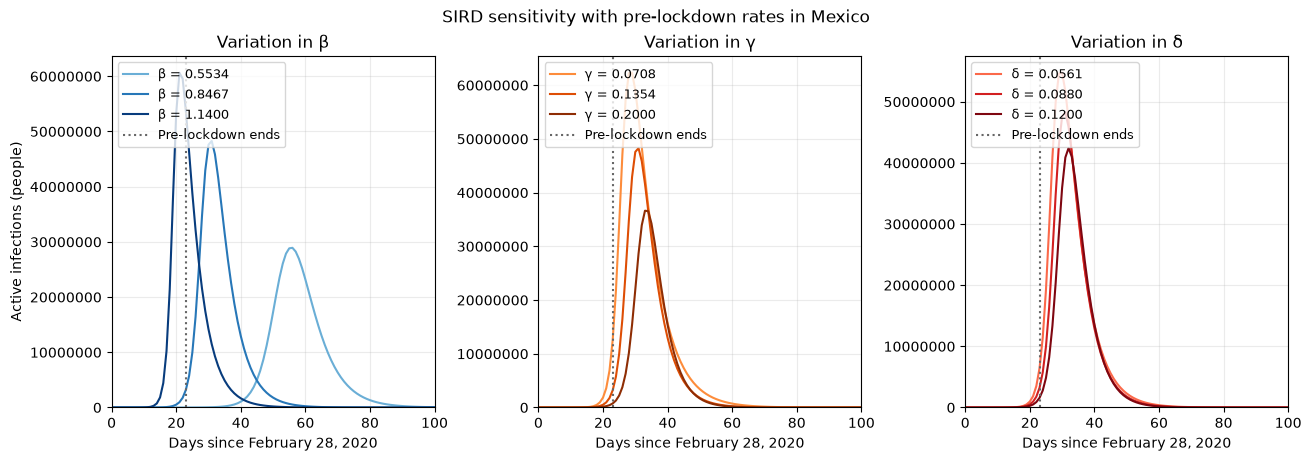

In [3]:
symbols = {"beta": "β", "gamma": "γ", "delta": "δ"}
palettes = {"beta": "Blues", "gamma": "Oranges", "delta": "Reds"}
curves = {}
for key, values in rates.items():
    curves[key] = []
    for value in values:
        params = {**midpoints, key: value}
        _, counts, _ = SIRD_simulation(**params, N=population, y0=initial_counts,
                                       t_max=last_day, verbose=False)
        curves[key].append(counts[:, 1])


def sensitivity_figure():
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), layout="constrained")
    lines = []
    for ax, key in zip(axes, rates):
        colors = plt.colormaps[palettes[key]](np.linspace(0.5, 0.95, 3))
        for value, infected, color in zip(rates[key], curves[key], colors):
            line, = ax.plot(days, infected, color=color, label=f"{symbols[key]} = {value:.4f}")
            lines.append((line, infected))
        ax.set_title(f"Variation in {symbols[key]}")
        ax.set_xlim(0, last_day)
        ax.axvline(phase_end_day, color="0.4", linestyle=":", label="Pre-lockdown ends")
        ax.set_ylim(0, 1.05 * np.max(curves[key]))
        ax.set_xlabel("Days since February 28, 2020")
        ax.ticklabel_format(axis="y", style="plain", useOffset=False)
        ax.grid(alpha=0.25)
        ax.legend(loc="upper left", fontsize=9)
    axes[0].set_ylabel("Active infections (people)")
    return fig, lines


figure, _ = sensitivity_figure()
figure.suptitle("SIRD sensitivity with pre-lockdown rates in Mexico")
plt.show()

## Export daily trajectories and closing counts

In [4]:
daily = pd.concat(trajectories, ignore_index=True)
daily = daily[["scenario", "beta", "gamma", "delta", "date", "day", "S", "I", "R", "D"]]
daily_path = data_dir / "pre_lockdown_sird_all_results.csv"
summary_path = data_dir / "pre_lockdown_sird_compartment_summary.csv"
daily.to_csv(daily_path, index=False)
simulation_summary.to_csv(summary_path, index=False)
print(f"{daily_path.name}: {len(daily)} rows")
print(f"{summary_path.name}: {len(simulation_summary)} scenarios ending on {dates[-1]:%Y-%m-%d}")

pre_lockdown_sird_all_results.csv: 303 rows
pre_lockdown_sird_compartment_summary.csv: 3 scenarios ending on 2020-06-07


## Daily animation

Each frame reveals the next simulation date. The scales of the three panels match their respective static plots.

pre_lockdown_sird_sensitivity.gif: 101 daily frames


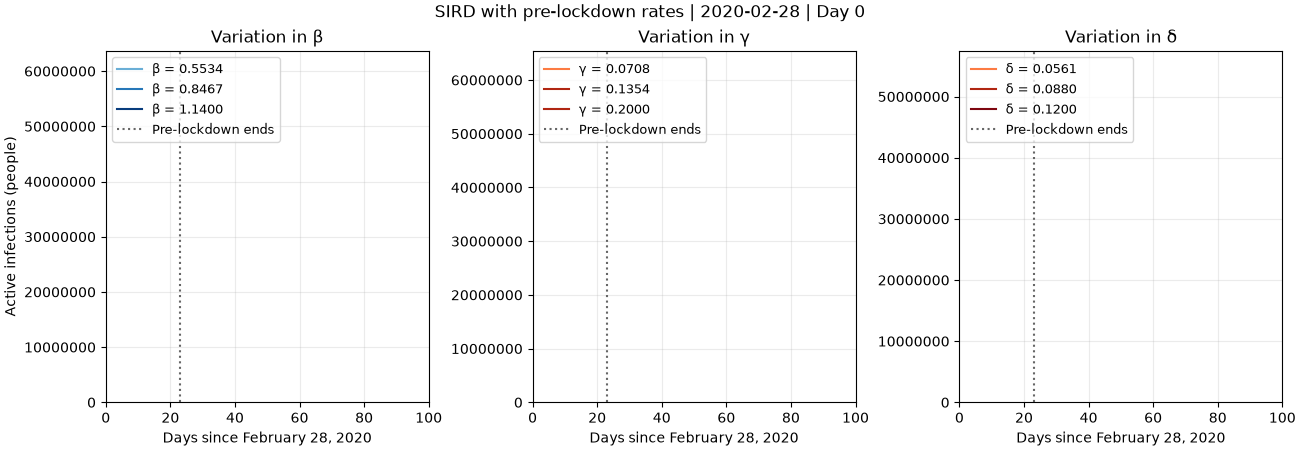

In [5]:
fps = 6
animation_path = data_dir / "pre_lockdown_sird_sensitivity.gif"
animation_figure, animated_curves = sensitivity_figure()
title = animation_figure.suptitle("")


def draw_day(day):
    for line, infected in animated_curves:
        line.set_data(days[:day + 1], infected[:day + 1])
    title.set_text(f"SIRD with pre-lockdown rates | {dates[day]:%Y-%m-%d} | Day {day}")


animation = FuncAnimation(animation_figure, draw_day, frames=len(dates), interval=1000 / fps)
animation.save(animation_path, writer=PillowWriter(fps=fps), dpi=100)
plt.close(animation_figure)
print(f"{animation_path.name}: {len(dates)} daily frames")
display(Image(filename=str(animation_path)))